# 3.0 Versión oficial: entrada del modelo, validación y viajes marcados

El data engineer fijó la versión oficial de 2025: conserva todos los viajes y agrega `duracion_segundos`, `duracion_no_positiva` y `duracion_mayor_24h`. Para modelar solo se excluyen los viajes con duración cero o negativa. Este notebook revisa esa entrada, valida la tabla de demanda que se construye con ella y analiza los viajes marcados.

In [1]:
import mlflow
import pandas as pd
from IPython.display import Image, display
from loguru import logger

from mibici_mlops.config import FIGURES_DIR, MLFLOW_TRACKING_URI, REPORTS_DIR
from mibici_mlops.model_input import load_official_trips, model_trips

logger.disable('mibici_mlops')
oficial, archivos = load_official_trips()
modelo, conteos = model_trips(oficial)
print(f'{len(oficial):,} viajes en la versión oficial, {len(modelo):,} para modelar')
conteos

/home/fgrodriguez/mibici-mlops/.venv/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
2026-10-25 15:11:08.395 | INFO     | mibici_mlops.config:<module>:12 - PROJ_ROOT path is: /home/fgrodriguez/mibici-mlops


4,532,032 viajes en la versión oficial, 4,529,252 para modelar


{'marcados_duracion_no_positiva': 2780,
 'marcados_duracion_mayor_24h': 6,
 'excluidos_para_modelo': 2780}

## Validación de la tabla de demanda

Generada por `python -m mibici_mlops.validation`.

In [2]:
pd.read_csv(REPORTS_DIR / 'validacion_demanda_oficial.csv')

,prueba,resultado,detalle
0,horas completas por estacion,cumple,"371 estaciones; esperadas 8,760 horas cada una..."
1,sin estacion-hora repetida,cumple,0 repetidas
2,horas dentro de 2025,cumple,0 fuera de rango
3,salidas cuadran con viajes,cumple,"salidas 4,529,252; viajes que inician en 2025 ..."
4,llegadas cuadran con viajes,cumple,"llegadas 4,529,245; viajes que terminan en 202..."
5,salidas por mes cuadran,cumple,0 meses con diferencia
6,conteos no negativos,cumple,0 filas negativas
7,neto = llegadas - salidas,cumple,revisado en todas las filas
8,estaciones en el catalogo,cumple,0 fuera del catalogo []


## Viajes marcados

Las dos primeras filas son banderas oficiales. Las otras tres son casos que este análisis propone revisar; no se excluyen.

In [3]:
pd.read_csv(REPORTS_DIR / 'eda_viajes_marcados.csv')

,categoria,tipo,viajes,pct_del_total,pct_misma_estacion,mediana_min,estaciones
0,duracion_no_positiva,bandera oficial (se excluye),2780,0.061,22.5,0.00,344
1,duracion_mayor_24h,bandera oficial (se conserva),6,0.000,33.3,1647.62,6
2,misma_estacion_menos_2_min,por revisar,123158,2.718,100.0,0.37,371
3,distinta_estacion_menos_1_min,por revisar,5807,0.128,0.0,0.03,367
4,entre_3_y_24_horas,por revisar,448,0.010,19.6,280.12,218


Los viajes de distinta estación en menos de un minuto tienen una mediana de unos dos segundos: no son viajes posibles y apuntan a un error de registro. Los de la misma estación en menos de dos minutos son 2.7 % del total.

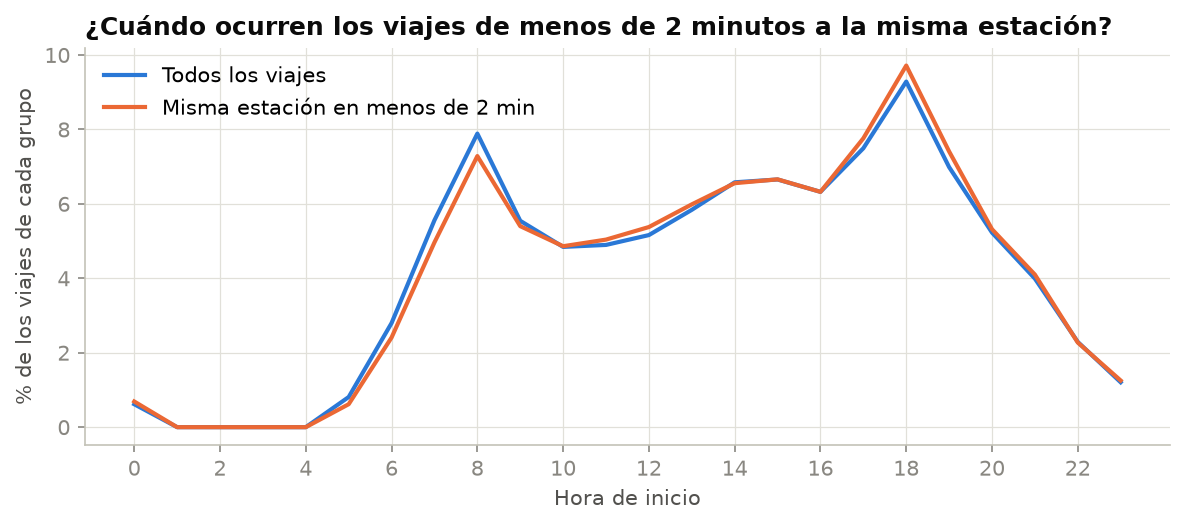

In [4]:
display(Image(FIGURES_DIR / '11_marcados_por_hora.png'))

Siguen casi la misma curva horaria que el resto de los viajes, con los mismos picos de las 8 y las 18 h: no se concentran en un horario.

estaciones con 1,000 salidas o más: 368
mediana del % de salidas marcadas: 2.84
estaciones con más de 10 %: 0


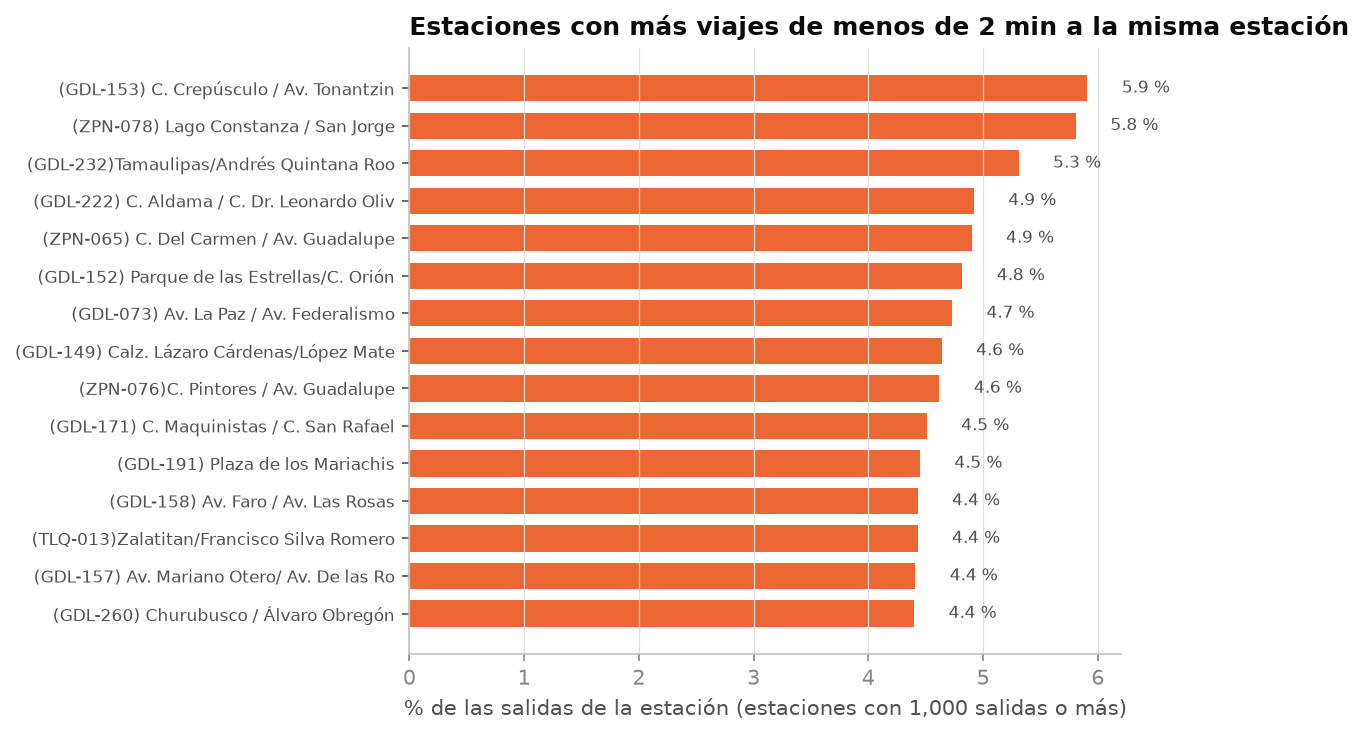

In [5]:
por_estacion = pd.read_csv(REPORTS_DIR / 'eda_viajes_marcados_por_estacion.csv')
grandes = por_estacion[por_estacion['salidas'] >= 1000]
print('estaciones con 1,000 salidas o más:', len(grandes))
print('mediana del % de salidas marcadas:', grandes['pct_marcadas'].median())
print('estaciones con más de 10 %:', int((grandes['pct_marcadas'] > 10).sum()))
display(Image(FIGURES_DIR / '12_marcados_por_estacion.png'))

Tampoco se concentran en pocas estaciones: ninguna supera el 6 % de sus salidas. Conservarlos sube la demanda de forma pareja, sin cambiar el patrón.

## Líneas base contra la versión oficial

In [6]:
mlflow.set_tracking_uri(MLFLOW_TRACKING_URI)
exp = mlflow.search_runs(experiment_names=['MiBici_Fase1_Experimentos_Datos'])
exp = exp[exp['params.variante_verdad'] == 'oficial'].drop_duplicates('params.variante_datos')
m = [c for c in exp.columns if c.startswith('metrics.salidas')]
exp.set_index('params.variante_datos')[m].T.round(3)

params.variante_datos,laxa,estricta,oficial
metrics.salidas_promedio_historico_mae,0.856,0.848,0.856
metrics.salidas_promedio_historico_mae_pico,1.469,1.449,1.469
metrics.salidas_misma_hora_semana_pasada_rmse,1.909,1.867,1.909
metrics.salidas_misma_hora_semana_pasada_mae_pico,1.608,1.576,1.608
metrics.salidas_misma_hora_semana_pasada_mae,0.990,0.971,0.990
metrics.salidas_promedio_historico_rmse,1.546,1.536,1.546


Con la versión oficial como verdad, la línea base de referencia queda en un MAE de 0.856. Entrenar con la variante estricta lo baja a 0.848 (alrededor de 1 %), así que quitar los viajes de menos de dos minutos a la misma estación ayuda poco. Esto respalda conservarlos marcados, como decidió el data engineer.